# Online Retail Analysis (Dec 2010 to Dec 2011)

**Data:** transactions of a UK online gift shop, 1 Dec 2010 to 9 Dec 2011 (541,909 rows, 8 columns).
**Tools:** Python (pandas) for cleaning and analysis. The cleaned data is exported to build a Power BI dashboard.
**Author:** (write your name here)

**Contents**
1. Business question
2. Setup and load data
3. Understand the data
4. Clean the data
5. Q1: Sales over time
6. Q2: Top products
7. Q3: Countries
8. Q4: Cancellations
9. Q5: Customers (RFM)
10. Insights and actions
11. Export for Power BI

## 1. Business question

> Where does the shop's money come from, who are the most valuable customers, and what is hurting sales?

This is split into five smaller questions. Each one comes from something I noticed in the data.

| # | Question | Why I ask it |
|---|---|---|
| 1 | How do sales change month by month, and when is the peak? | The data covers about one year, and the last month is partial |
| 2 | Which products bring the most money? | One product (22423) appears very often in cancellations |
| 3 | Which countries bring the most money? | The Country column has more than the UK |
| 4 | How much money is lost to cancellations? | Invoices starting with "C" are cancellations |
| 5 | Who are the best customers, and who is slipping away? | CustomerID exists for about 75% of rows |

## 2. Setup and load data

The Excel file takes 1 to 2 minutes to load. If your file is in another folder, change `DATA_PATH`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_PATH = "online_retail.xlsx"
df = pd.read_excel(DATA_PATH)
df.shape

(541909, 8)

## 3. Understand the data

**What each column means**

| Column | Meaning |
|---|---|
| InvoiceNo | Bill number. If it starts with "C", it is a cancellation |
| StockCode | Product code |
| Description | Product name |
| Quantity | Number of pieces |
| InvoiceDate | Date and time of the bill |
| UnitPrice | Price of one piece in pounds |
| CustomerID | Customer number |
| Country | Customer's country |

One invoice has many rows. One row is one product line, not a whole order.

In [2]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### 3.1 Things that look strange

Four things need a closer look: the huge Quantity values (min and max are both 80,995), the negative UnitPrice, zero prices, and the 25% missing CustomerID.

In [6]:
# The two rows with the biggest quantity
df[df["Quantity"].abs() == 80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


In [7]:
# Rows with a negative price
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [8]:
# Cancellations versus negative quantities
n_cancel = df["InvoiceNo"].astype(str).str.startswith("C").sum()
n_negqty = (df["Quantity"] < 0).sum()
print("Invoices starting with C:", n_cancel)
print("Rows with negative quantity:", n_negqty)
print("Difference:", n_negqty - n_cancel)

# Negative quantity but NOT a cancellation
neg_not_c = df[(df["Quantity"] < 0) & (~df["InvoiceNo"].astype(str).str.startswith("C"))]
print("Rows:", len(neg_not_c))
print("Share with price 0:", (neg_not_c["UnitPrice"] == 0).mean())
print("Share with no CustomerID:", neg_not_c["CustomerID"].isna().mean())

Invoices starting with C: 9288
Rows with negative quantity: 10624
Difference: 1336
Rows: 1336
Share with price 0: 1.0
Share with no CustomerID: 1.0


In [9]:
# Zero price rows
df[df["UnitPrice"] == 0].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [10]:
# Most expensive prices
df.sort_values("UnitPrice", ascending=False).head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom


In [11]:
# Stock codes that do not look like normal 5-digit product codes
odd = df[~df["StockCode"].astype(str).str.match(r"^\d{5}")]
odd["StockCode"].value_counts().head(15)

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
Name: count, dtype: int64

### 3.2 What I found

- **Missing CustomerID:** 135,080 rows (about 25%). Missing Description: 1,454 rows.
- **The 80,995-unit order:** invoice 581483 (9 Dec 2011, 09:15) was cancelled 12 minutes later by invoice C581484. Its value is about £168,470, so it can distort any total.
- **Negative price:** the 2 rows are "Adjust bad debt", an accounting entry, not a product.
- **Negative quantity has three different meanings:**

| Type | Quantity | Price | Invoice | CustomerID |
|---|---|---|---|---|
| Customer cancellation or return | negative | normal | starts with "C" | usually present |
| Stock adjustment | negative | 0 | normal | missing |
| Bad debt | +1 | negative | starts with "A" | missing |

- The 1,336 rows with negative quantity but no "C" all have price 0 and no CustomerID, so they are stock adjustments, not returns.
- **Non-product codes:** POST, DOT, M, C2, D, S, BANK CHARGES, AMAZONFEE, CRUK, B are postage, manual entries, discounts, samples, fees and bad debt. Codes such as `gift_0001_20` and `DCGS...` look odd but are real items, so a "5 digits" rule would be wrong. I use an explicit list instead.
- The shop also sells on Amazon (AMAZONFEE rows).

## 4. Clean the data

**Plan:** I do not delete rows I may need later. I label each row with a `RowType`, then each question uses only the rows it needs.

| Problem | Decision | Why |
|---|---|---|
| 5,268 exact duplicate rows | Remove | Same invoice, product, time and quantity. Probably entered twice |
| CustomerID stored as decimal | Convert to whole number | An ID is not a quantity. Missing values stay empty |
| 25% rows without CustomerID | Keep for revenue, leave out of customer analysis | The money is real, but we do not know who paid |
| Cancellations | Label and keep | Needed to calculate net sales |
| Non-product codes | Label and leave out of sales analysis | Not products |
| Zero price rows | Label and leave out of sales analysis | No revenue |

In [12]:
print("Rows before:", len(df))
print("Duplicate rows:", df.duplicated().sum())

dups = df[df.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"])
dups.head(10)

Rows before: 541909
Duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [13]:
removed = df[df.duplicated()]
removed_value = (removed["Quantity"] * removed["UnitPrice"]).sum()
total_value = (df["Quantity"] * df["UnitPrice"]).sum()
print("Value of removed duplicates:", round(removed_value))
print("Share of total value (%):", round(removed_value / total_value * 100, 2))

Value of removed duplicates: 21741
Share of total value (%): 0.22


In [14]:
# Step 1: remove duplicates
df_clean = df.drop_duplicates().copy()

# Step 2: CustomerID as whole number (missing values stay empty)
df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")

# Step 3: label every row
non_product_codes = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B"]

is_nonprod = df_clean["StockCode"].astype(str).isin(non_product_codes)
is_cancel = df_clean["InvoiceNo"].astype(str).str.startswith("C")
is_zero = df_clean["UnitPrice"] <= 0

# The order of these rules matters: the first true rule wins
df_clean["RowType"] = np.select(
    [is_nonprod, is_cancel, is_zero],
    ["Non-product", "Cancellation", "Zero price"],
    default="Sale",
)

# Step 4: revenue per row
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Two working tables
df_sales = df_clean[df_clean["RowType"] == "Sale"].copy()
df_net = df_clean[df_clean["RowType"].isin(["Sale", "Cancellation"])].copy()

print("Rows after:", len(df_clean), "| removed:", len(df) - len(df_clean))
df_clean["RowType"].value_counts()

Rows after: 536641 | removed: 5268


RowType
Sale            522572
Cancellation      8668
Non-product       2905
Zero price        2496
Name: count, dtype: int64

### Cleaning log

| Step | What I did | Rows before | Rows after | Why |
|---|---|---|---|---|
| 1 | Removed exact duplicates | 541,909 | 536,641 | Same row twice. Impact is small: about £21,700, or 0.22% of revenue |
| 2 | CustomerID to whole number | 536,641 | 536,641 | It was decimal only because of the missing values |
| 3 | Added `RowType` label (Sale, Cancellation, Non-product, Zero price) | 536,641 | 536,641 | Nothing deleted. Each question picks the rows it needs. Order of rules matters |
| 4 | Added `Revenue = Quantity x UnitPrice` | 536,641 | 536,641 | Needed for every sales question |

Result: 522,572 Sale rows, 8,668 Cancellation rows, 2,905 Non-product rows, 2,496 Zero price rows.

## 5. Q1: Sales over time

Gross sales use `Sale` rows. Net sales also subtract cancellations. I also divide by the number of trading days, because months have different lengths.

In [15]:
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M").astype(str)

monthly = df_sales.groupby("Month").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Days=("InvoiceDate", lambda s: s.dt.date.nunique()),
)

# Cancellations per month
cancel_month = (
    df_clean[df_clean["RowType"] == "Cancellation"]
    .assign(Month=lambda d: d["InvoiceDate"].dt.to_period("M").astype(str))
    .groupby("Month")["Revenue"].sum()
)

monthly["Cancelled"] = cancel_month.reindex(monthly.index).fillna(0)
monthly["Net"] = monthly["Revenue"] + monthly["Cancelled"]
monthly["PerDay"] = (monthly["Revenue"] / monthly["Days"]).round(0)
monthly["NetPerDay"] = (monthly["Net"] / monthly["Days"]).round(0)
monthly["AOV"] = (monthly["Revenue"] / monthly["Orders"]).round(0)
monthly.round(0)

,Revenue,Orders,Days,Cancelled,Net,PerDay,NetPerDay,AOV
Month,,,,,,,,
2010-12,775718.0,1550,20,-17548.0,758170.0,38786.0,37908.0,500.0
2011-01,670439.0,1081,24,-91525.0,578914.0,27935.0,24121.0,620.0
2011-02,507867.0,1093,24,-8336.0,499531.0,21161.0,20814.0,465.0
2011-03,689842.0,1440,27,-10504.0,679338.0,25550.0,25161.0,479.0
2011-04,515470.0,1235,21,-33316.0,482154.0,24546.0,22960.0,417.0
2011-05,740036.0,1668,25,-8948.0,731088.0,29601.0,29244.0,444.0
2011-06,737684.0,1525,26,-13714.0,723970.0,28372.0,27845.0,484.0
2011-07,688253.0,1452,26,-11407.0,676845.0,26471.0,26033.0,474.0
2011-08,724308.0,1339,26,-22927.0,701382.0,27858.0,26976.0,541.0


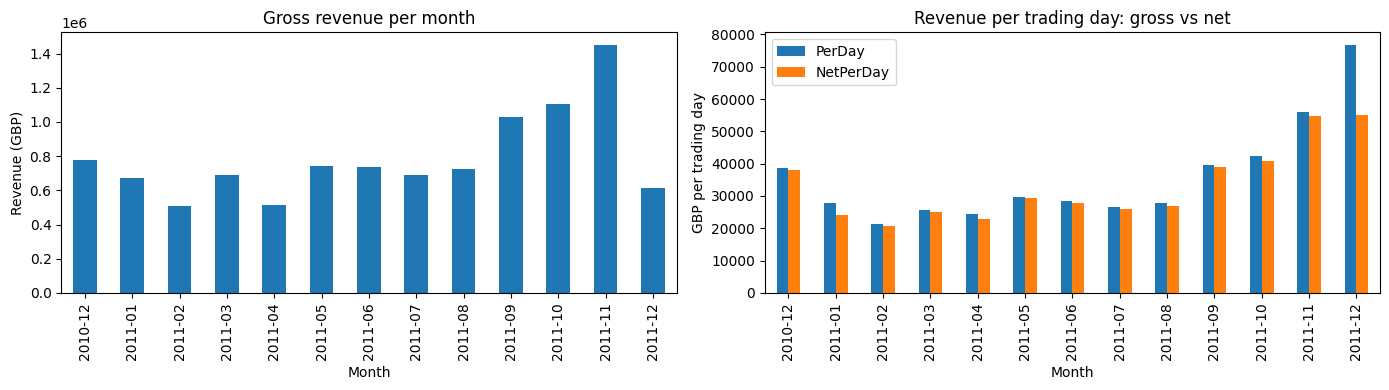

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly["Revenue"].plot(kind="bar", ax=ax[0], title="Gross revenue per month")
ax[0].set_ylabel("Revenue (GBP)")
monthly[["PerDay", "NetPerDay"]].plot(kind="bar", ax=ax[1], title="Revenue per trading day: gross vs net")
ax[1].set_ylabel("GBP per trading day")
plt.tight_layout()
plt.show()

### Findings

- **Peak month:** November 2011 (gross about £1.45M). Sales rise strongly from September to November, which is typical for a gift shop before Christmas.
- **Partial months:** December 2011 has only 8 trading days (data ends 9 Dec) and December 2010 has 20 (data ends 23 Dec). There are no Saturday sales in the data. Comparing total revenue of these months with full months is misleading.
- **A trap in December 2011:** gross revenue per day makes December look like the best month (about £76,800 per day). But that includes the 80,995-unit order of about £168,000 that was cancelled 12 minutes later. On a **net** basis, December runs at about £55,000 per day, the same pace as November.
- **Lesson:** gross and net sales are different. A huge order and its cancellation can change the story of a whole month.

## 6. Q2: Top products

First by gross revenue (Sale rows only), then by net revenue (Sale minus cancellations).

In [17]:
def mode_or_none(s):
    m = s.mode()
    return m.iat[0] if not m.empty else None

top_gross = (
    df_sales.groupby("StockCode")
    .agg(Description=("Description", mode_or_none), Revenue=("Revenue", "sum"), Units=("Quantity", "sum"))
    .sort_values("Revenue", ascending=False)
    .head(10)
)
top_gross

,Description,Revenue,Units
StockCode,,,
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641
47566,PARTY BUNTING,99445.23,18283
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
23084,RABBIT NIGHT LIGHT,66870.03,30739
22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362


In [18]:
top_net = (
    df_net.groupby("StockCode")
    .agg(Description=("Description", mode_or_none), NetRevenue=("Revenue", "sum"), NetUnits=("Quantity", "sum"))
    .sort_values("NetRevenue", ascending=False)
    .head(10)
)
top_net["AvgPrice"] = (top_net["NetRevenue"] / top_net["NetUnits"]).round(2)
top_net

,Description,NetRevenue,NetUnits,AvgPrice
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,164459.49,12996,12.65
47566,PARTY BUNTING,98243.88,18006,5.46
85123A,WHITE HANGING HEART T-LIGHT HOLDER,97838.45,35063,2.79
85099B,JUMBO BAG RED RETROSPOT,92175.79,47256,1.95
23084,RABBIT NIGHT LIGHT,66661.63,30631,2.18
22086,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24,18876,3.38
84879,ASSORTED COLOUR BIRD ORNAMENT,58792.42,36282,1.62
79321,CHILLI LIGHTS,53746.66,10222,5.26
22502,PICNIC BASKET WICKER SMALL,51023.52,1862,27.40


### Findings

- In the gross list, **PAPER CRAFT, LITTLE BIRDIE (80,995 units)** and **MEDIUM CERAMIC TOP STORAGE JAR (78,033 units)** are in the top 10. Both are the huge orders that were cancelled within minutes. They leave the list when cancellations are subtracted.
- A quick check for strange items: divide revenue by units. The jar sold for about £1 a piece but had 78,000 units, which pointed to one giant order.
- **Net top product:** REGENCY CAKESTAND 3 TIER (about £164,000).
- There are two kinds of top products: cheap and high volume (POPCORN HOLDER: £0.90 a piece, 56,427 units) and expensive and low volume (PICNIC BASKET WICKER SMALL: £27.40 a piece, 1,862 units). Both bring about £51,000.

## 7. Q3: Countries

In [19]:
sales_by_country = df_sales.groupby("Country").agg(
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique"),
)
net_by_country = df_net.groupby("Country")["Revenue"].sum().rename("NetRevenue")

country = pd.concat([net_by_country, sales_by_country], axis=1).sort_values("NetRevenue", ascending=False)
country["Share_%"] = (country["NetRevenue"] / country["NetRevenue"].sum() * 100).round(1)
country["PerCustomer"] = (country["NetRevenue"] / country["Customers"]).round(0)
country.head(10)

,NetRevenue,Orders,Customers,Share_%,PerCustomer
Country,,,,,
United Kingdom,8282078.723,17901,3916,84.8,2115.0
Netherlands,283479.540,93,9,2.9,31498.0
EIRE,259380.020,282,3,2.7,86460.0
Germany,200619.660,443,94,2.1,2134.0
France,182076.600,382,87,1.9,2093.0
Australia,136922.500,56,9,1.4,15214.0
Switzerland,52483.050,50,21,0.5,2499.0
Spain,51746.650,88,30,0.5,1725.0
Belgium,36662.960,98,25,0.4,1467.0


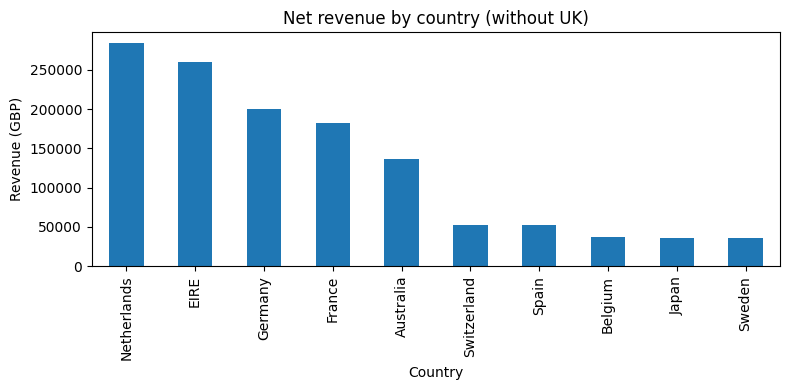

In [20]:
country.drop("United Kingdom").head(10)["NetRevenue"].plot(kind="bar", figsize=(8, 4), title="Net revenue by country (without UK)")
plt.ylabel("Revenue (GBP)")
plt.tight_layout()
plt.show()

In [21]:
# Who is behind the countries with very few customers?
for ctry in ["Netherlands", "Australia", "EIRE"]:
    print(ctry)
    print(df_net[df_net["Country"] == ctry].groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(3))
    print()

Netherlands
CustomerID
14646    278778.02
12759      1411.44
12775      1246.24
Name: Revenue, dtype: float64

Australia
CustomerID
12415    123638.18
12431      5376.11
12388      2780.66
Name: Revenue, dtype: float64

EIRE
CustomerID
14911    128768.24
14156    113685.77
14016      4278.46
Name: Revenue, dtype: float64



### Findings

- **The UK gives about 85% of net revenue.** Next are Netherlands, EIRE, Germany, France and Australia.
- UK, Germany and France customers spend about the same on average (about £2,100 per customer). Germany and France have around 90 customers each.
- **Netherlands, EIRE and Australia depend on very few customers.** EIRE has 3 customers (about £86,000 each). Netherlands has 9 customers, and one of them gives about 98% of the identified revenue. In Australia one customer gives about 90%.
- These three should be treated as key accounts, not as country markets. Losing one customer would remove most of a country's sales.

## 8. Q4: Cancellations

In [22]:
gross = df_sales["Revenue"].sum()
cancelled = -df_clean[df_clean["RowType"] == "Cancellation"]["Revenue"].sum()

print("Gross sales:", round(gross))
print("Cancelled:", round(cancelled))
print("Cancelled % of gross:", round(cancelled / gross * 100, 2))

Gross sales: 10247908
Cancelled: 475901
Cancelled % of gross: 4.64


In [23]:
# The two huge orders that were cancelled
big = df_clean[(df_clean["RowType"] == "Cancellation") & (df_clean["Quantity"].abs() > 70000)]
big_value = -big["Revenue"].sum()
print(big[["InvoiceNo", "StockCode", "Quantity", "Revenue"]])

print("Value of the two cancellations:", round(big_value))
print("Share of all cancelled value (%):", round(big_value / cancelled * 100, 1))

# Their original orders are inside gross sales, so remove them from both sides
rate_without = (cancelled - big_value) / (gross - big_value) * 100
print("Cancellation rate without them (%):", round(rate_without, 2))

       InvoiceNo StockCode  Quantity   Revenue
61624    C541433     23166    -74215  -77183.6
540422   C581484     23843    -80995 -168469.6
Value of the two cancellations: 245653
Share of all cancelled value (%): 51.6
Cancellation rate without them (%): 2.3


In [24]:
canc = df_clean[df_clean["RowType"] == "Cancellation"]
(
    canc.groupby("StockCode")
    .agg(Description=("Description", mode_or_none), CancelledValue=("Revenue", "sum"), Lines=("InvoiceNo", "count"))
    .sort_values("CancelledValue")
    .head(10)
)

,Description,CancelledValue,Lines
StockCode,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",-168469.60,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,-77479.64,10
22423,REGENCY CAKESTAND 3 TIER,-9697.05,180
85123A,WHITE HANGING HEART T-LIGHT HOLDER,-6624.30,42
21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-6591.42,3
23113,PANTRY CHOPPING BOARD,-4803.06,6
48185,DOORMAT FAIRY CAKE,-4554.90,3
21175,GIN + TONIC DIET METAL SIGN,-3775.33,7
47566B,TEA TIME PARTY BUNTING,-3692.95,7


### Findings

- Cancellations are about **£476,000, or 4.64% of gross sales**.
- About half of that (about £245,650) comes from two huge orders (80,995 and 74,215 units) that were reversed within minutes. Without them the normal cancellation rate is about **2.3%**. Both numbers should be reported, with the reason.
- After those two, the next largest cancelled product is only about £9,700, so the top of the list is not a fair picture of the problem.
- There are two patterns: frequent small cancellations (REGENCY CAKESTAND: 180 lines, about £54 each) and rare large ones (FAIRY CAKE FLANNEL: 3 lines, about £2,200 each).
- The Regency Cakestand is the best seller and is cancelled about 5.6% of its gross sales, more than double the shop average. The reason (breakage, packaging, wrong description) should be checked.

## 9. Q5: Customers (RFM)

**RFM** describes each customer with three numbers:

| Letter | Meaning | Better is |
|---|---|---|
| R: Recency | Days since the last purchase | smaller |
| F: Frequency | Number of orders | bigger |
| M: Monetary | Total net money spent | bigger |

Monetary uses **net** revenue so cancelled orders do not make anyone look like a best customer. Customers with net spend of zero or less are left out. Only rows with a CustomerID can be used.

In [25]:
snapshot = df_sales["InvoiceDate"].max() + pd.Timedelta(days=1)
last_buy = df_sales.groupby("CustomerID")["InvoiceDate"].max()

rfm = pd.DataFrame({
    "Recency": (snapshot - last_buy).dt.days,
    "Frequency": df_sales.groupby("CustomerID")["InvoiceNo"].nunique(),
    "Monetary": df_net.groupby("CustomerID")["Revenue"].sum(),
})
rfm = rfm[rfm["Monetary"] > 0].copy()
rfm[["Recency", "Frequency"]] = rfm[["Recency", "Frequency"]].astype(int)

print("Customers:", len(rfm))
rfm.describe().round(1)

Customers: 4325


,Recency,Frequency,Monetary
count,4325.0,4325.0,4325.0
mean,92.5,4.3,1912.1
std,100.1,7.6,8299.2
min,1.0,1.0,0.0
25%,18.0,1.0,298.2
50%,51.0,2.0,648.4
75%,143.0,5.0,1607.1
max,374.0,206.0,278778.0


Monetary mean (about £1,900) is three times the median (about £650). A few very big customers pull the average up, so the median describes a typical customer better. The largest value (about £278,800) is the single Netherlands customer.

In [26]:
# Scores from 1 to 5 (5 is best). Recency is reversed because fewer days is better.
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head()

,Recency,Frequency,Monetary,R,F,M
CustomerID,,,,,,
12347,2,7,4310.00,5,5,5
12348,75,4,1437.24,2,4,4
12349,19,1,1457.55,4,1,4
12350,310,1,294.40,1,1,2
12352,36,7,1265.41,3,5,4


### Segments

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R >= 4 and F >= 4 | Bought recently and often |
| Loyal | R >= 3 and F >= 3 | Regular customers |
| Promising | R >= 4 and F <= 2 | New, only one or two orders so far |
| At Risk | R <= 2 and F >= 3 | Used to buy often, now silent |
| Lost | R <= 2 and F <= 2 | Few orders and gone for a long time |
| Need Attention | everything else | Middle recency, low frequency |

The order of the rules matters: the first true rule wins.

In [27]:
R, F = rfm["R"], rfm["F"]

rfm["Segment"] = np.select(
    [
        (R >= 4) & (F >= 4),
        (R >= 3) & (F >= 3),
        (R >= 4) & (F <= 2),
        (R <= 2) & (F >= 3),
        (R <= 2) & (F <= 2),
    ],
    ["Champions", "Loyal", "Promising", "At Risk", "Lost"],
    default="Need Attention",
)

summary = rfm.groupby("Segment").agg(
    Customers=("Monetary", "size"),
    Revenue=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgSpend=("Monetary", "mean"),
).round(0)
summary["Cust_%"] = (summary["Customers"] / summary["Customers"].sum() * 100).round(1)
summary["Rev_%"] = (summary["Revenue"] / summary["Revenue"].sum() * 100).round(1)
summary.sort_values("Revenue", ascending=False)

,Customers,Revenue,AvgRecency,AvgFrequency,AvgSpend,Cust_%,Rev_%
Segment,,,,,,,
Champions,1114,5627024.0,13.0,10.0,5051.0,25.8,68.0
Loyal,824,1150666.0,37.0,4.0,1396.0,19.1,13.9
At Risk,657,774316.0,150.0,3.0,1179.0,15.2,9.4
Lost,1073,429268.0,217.0,1.0,400.0,24.8,5.2
Need Attention,346,150473.0,52.0,1.0,435.0,8.0,1.8
Promising,311,137891.0,18.0,1.0,443.0,7.2,1.7


In [28]:
# How much net revenue has no CustomerID at all?
no_id_share = df_net.loc[df_net["CustomerID"].isna(), "Revenue"].sum() / df_net["Revenue"].sum()
print("Net revenue without CustomerID (%):", round(no_id_share * 100, 1))

Net revenue without CustomerID (%): 15.4


In [30]:
### Findings

- **Champions are about 26% of customers but give about 68% of the revenue.** Lost customers are about the same number (1,073 vs 1,114) but give only about 5%.
- **At Risk:** 657 customers who earlier spent about £774,000 (about £1,180 each) and have been silent for about 150 days on average. A typical customer returns within about 50 days, so these are worth a win-back effort.
- **Lost:** about 1,070 customers, each spent about £400 in a single order and have been gone for about 217 days. Not worth chasing.

**Limits of this analysis**
- Only customers with a CustomerID are included. About 15% of net revenue has no CustomerID, so the 68% is a share of identified customers' revenue.
- The data covers one year only. A "Lost" customer may just be seasonal.

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (3793277654.py, line 3)

## 10. Insights and actions
| # | What we found | What the owner should do |
|---|---|---|
| 1 | Sales grow from September to November. Net revenue per trading day goes from about £39K (Sep) to about £55K (Nov). The first 9 days of December 2011 stay at the same pace | Order stock and plan staff by August. Start Christmas promotions in September. Check the pattern again with a second year of data |
| 2 | The UK gives about 85% of net revenue. Germany and France each have about 90 customers who spend about the same per customer as UK customers (about £2,100) | Keep UK delivery and stock reliable first. Then test growth in Germany and France |
| 3 | Netherlands, EIRE and Australia depend on 1 to 3 customers. One customer gives about 98% of the identified Netherlands revenue | Treat them as key accounts. Give each a named contact, talk to them regularly, and watch their orders every month |
| 4 | The cancellation rate is 4.64%, but about half of the cancelled value comes from two huge orders cancelled within minutes. Without them the rate is about 2.3%. Regency Cakestand is returned more often than average (about 5.6%) | Add a confirmation step for orders far above normal size. Check why the Regency Cakestand comes back |
| 5 | Champions are about 26% of identified customers but give about 68% of their revenue. The 657 At Risk customers spent about £774K earlier but have been silent for about 150 days. Lost customers spent about £400 each, once | Protect Champions with early access and thank-you offers. Run a win-back campaign for the top 100 At Risk customers by spend, and measure how many return. Do not spend money chasing Lost customers |
| 6 | About 15% of net revenue has no CustomerID | Ask for a customer ID (or email) on every order, so more sales can be analysed by customer |

## 11. Export for Power BI

Two files are saved in the same folder as this notebook. Revenue is rounded to 2 decimals.

In [31]:
df_clean.assign(Revenue=df_clean["Revenue"].round(2)).to_csv("retail_clean.csv", index=False)
rfm.assign(Monetary=rfm["Monetary"].round(2)).reset_index().to_csv("rfm_segments.csv", index=False)
print("Saved retail_clean.csv and rfm_segments.csv")

Saved retail_clean.csv and rfm_segments.csv


**Next step:** build a 3-page Power BI dashboard (Overview, Products and Countries, Customers) from these two files.

In [32]:
products = (
    df_clean.groupby("StockCode")["Description"]
    .agg(lambda s: s.mode().iat[0] if not s.mode().empty else None)
    .reset_index()
    .rename(columns={"Description": "ProductName"})
)
products.to_csv("products.csv", index=False)
print("Saved products.csv:", len(products), "products")

Saved products.csv: 4070 products
